# Deep Learning / NLP Text Classifier with PyTorch
**Task:** Build, train, validate, and test a text-classification pipeline.  
**Example project:** Sentiment analysis (positive / negative)  
**Student deliverable:** Jupyter Notebook (`.ipynb`) with preprocessing, TF–IDF vectorization, a multilayer neural network, validation curves, and confidence-scored inference.

> This notebook is designed to run without downloading a dataset. It uses a small, clearly labelled example dataset embedded below. For a stronger real-world project, replace it with a larger approved dataset and rerun all cells.

## 1. Objectives and workflow
1. Load labelled text examples and inspect class balance.
2. Split the data into training and validation sets.
3. Convert text into TF–IDF feature vectors (fit only on training text to avoid data leakage).
4. Train a multilayer PyTorch neural network with Batch Normalization, Dropout, and early stopping.
5. Plot training/validation loss and accuracy.
6. Evaluate the held-out validation set and predict unseen sentences with confidence scores.

In [1]:
# If PyTorch is missing in your environment, uncomment and run:
# %pip install torch scikit-learn matplotlib pandas

import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Training device:", device)

PyTorch: 2.10.0+cpu
Training device: cpu


## 2. Prepare a labelled example dataset
The examples below are compact demonstration data, not a benchmark dataset. The notebook is self-contained so it can run in restricted notebook environments. Use a larger real dataset for a production-quality classifier.

In [2]:
positive = [
"I loved this movie, the acting was excellent",
"Wonderful story and brilliant performances",
"This product works perfectly and feels reliable",
"The service was friendly quick and helpful",
"I am very happy with this purchase",
"Fantastic quality and great value for money",
"The food was delicious and freshly prepared",
"An enjoyable experience from beginning to end",
"The app is easy to use and very useful",
"Great support team solved my problem quickly",
"Beautiful design and smooth performance",
"I would recommend this to all my friends",
"The book was engaging and inspiring",
"Everything arrived on time and in good condition",
"Excellent experience, I will buy again",
"The staff were kind and professional",
"Really impressed with the quality",
"This was better than I expected",
"Comfortable, simple, and well made",
"A delightful surprise and a great result",
"The film was funny and emotionally moving",
"Fast delivery and careful packaging",
"Clear instructions made setup easy",
"The update fixed the issue and improved speed",
"Pleasant atmosphere and tasty food",
"Helpful features make my work easier",
"Strong performance and dependable results",
"Customer care was patient and respectful",
"I enjoyed every minute of the event",
"Good value and a satisfying experience",
"Superb quality, highly recommended",
"Bright display and responsive controls",
"The lesson was clear and informative",
"Very pleased with the final outcome",
"Efficient service with no complications",
"The design is attractive and practical",
"Fresh ingredients and excellent flavour",
"Easy installation and reliable operation",
"The team handled everything professionally",
"A positive experience overall",
]
negative = [
"I hated this movie, the acting was terrible",
"Awful story and very poor performances",
"This product broke quickly and feels cheap",
"The service was rude slow and unhelpful",
"I am very unhappy with this purchase",
"Terrible quality and a waste of money",
"The food was cold and tasteless",
"A frustrating experience from beginning to end",
"The app is confusing and barely useful",
"Support ignored my problem for days",
"Ugly design and poor performance",
"I would not recommend this to anyone",
"The book was boring and disappointing",
"Everything arrived late and damaged",
"Bad experience, I will not buy again",
"The staff were careless and impolite",
"Really disappointed with the quality",
"This was much worse than I expected",
"Uncomfortable, complicated, and poorly made",
"A horrible surprise and a bad result",
"The film was dull and emotionally empty",
"Slow delivery and damaged packaging",
"Unclear instructions made setup difficult",
"The update caused errors and reduced speed",
"Unpleasant atmosphere and terrible food",
"Missing features make my work harder",
"Weak performance and unreliable results",
"Customer care was impatient and disrespectful",
"I regretted every minute of the event",
"Poor value and a frustrating experience",
"Awful quality, not recommended",
"Dim display and unresponsive controls",
"The lesson was confusing and uninformative",
"Very disappointed with the final outcome",
"Inefficient service with many complications",
"The design is unattractive and impractical",
"Stale ingredients and unpleasant flavour",
"Difficult installation and unreliable operation",
"The team handled everything unprofessionally",
"A negative experience overall",
]
df = pd.DataFrame({
    "text": positive + negative,
    "label": [1] * len(positive) + [0] * len(negative)
})
df["sentiment"] = df["label"].map({0: "negative", 1: "positive"})
print("Dataset shape:", df.shape)
display(df.sample(6, random_state=SEED))
print("\nClass counts:")
display(df["sentiment"].value_counts().to_frame("count"))

Dataset shape: (80, 3)


,text,label,sentiment
30,"Superb quality, highly recommended",1,positive
0,"I loved this movie, the acting was excellent",1,positive
22,Clear instructions made setup easy,1,positive
31,Bright display and responsive controls,1,positive
18,"Comfortable, simple, and well made",1,positive
28,I enjoyed every minute of the event,1,positive



Class counts:


,count
sentiment,
positive,40
negative,40


## 3. Split data and vectorize text
TF–IDF gives more weight to informative words. The vectorizer is fitted on the training split only; validation text is transformed using that already-fitted vectorizer.

In [3]:
X_train_text, X_val_text, y_train, y_val = train_test_split(
    df["text"].values,
    df["label"].values,
    test_size=0.25,
    random_state=SEED,
    stratify=df["label"].values
)

vectorizer = TfidfVectorizer(
    lowercase=True,
    strip_accents="unicode",
    ngram_range=(1, 2),
    max_features=3000,
    sublinear_tf=True
)
X_train = vectorizer.fit_transform(X_train_text).toarray().astype(np.float32)
X_val = vectorizer.transform(X_val_text).toarray().astype(np.float32)

y_train_np = y_train.astype(np.int64)
y_val_np = y_val.astype(np.int64)

print("Training examples:", len(y_train_np))
print("Validation examples:", len(y_val_np))
print("TF-IDF feature count:", X_train.shape[1])

Training examples: 60
Validation examples: 20
TF-IDF feature count: 420


## 4. Build a multilayer neural network
The network includes two hidden layers, ReLU activations, Batch Normalization, and Dropout. Cross-entropy loss is appropriate for two-class classification with two output logits.

In [4]:
class TextClassifier(nn.Module):
    def __init__(self, input_dim, num_classes=2):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.35),
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        return self.network(x)

model = TextClassifier(input_dim=X_train.shape[1]).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)

print(model)

TextClassifier(
  (network): Sequential(
    (0): Linear(in_features=420, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.35, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.25, inplace=False)
    (8): Linear(in_features=64, out_features=2, bias=True)
  )
)


## 5. Train with validation monitoring and early stopping
Early stopping ends training when validation loss does not improve for several epochs and restores the best model weights. The batch size is kept above one to make Batch Normalization safe for the final batch.

In [5]:
BATCH_SIZE = 8
train_ds = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train_np))
val_ds = TensorDataset(torch.from_numpy(X_val), torch.from_numpy(y_val_np))
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)

MAX_EPOCHS = 80
PATIENCE = 10
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_loss = float("inf")
best_state = None
epochs_without_improvement = 0

for epoch in range(MAX_EPOCHS):
    model.train()
    running_loss, train_correct, train_total = 0.0, 0, 0

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * len(yb)
        train_correct += (logits.argmax(dim=1) == yb).sum().item()
        train_total += len(yb)

    train_loss = running_loss / max(train_total, 1)
    train_acc = train_correct / max(train_total, 1)

    model.eval()
    val_loss_sum, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)
            val_loss_sum += loss.item() * len(yb)
            val_correct += (logits.argmax(dim=1) == yb).sum().item()
            val_total += len(yb)

    val_loss = val_loss_sum / max(val_total, 1)
    val_acc = val_correct / max(val_total, 1)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch {epoch+1:02d} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | train acc {train_acc:.3f} | val acc {val_acc:.3f}")

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping at epoch {epoch+1}.")
        break

if best_state is not None:
    model.load_state_dict(best_state)
print("Best validation loss:", round(best_val_loss, 4))

Epoch 01 | train loss 0.7306 | val loss 0.6940 | train acc 0.536 | val acc 0.500


Epoch 10 | train loss 0.1983 | val loss 1.0522 | train acc 1.000 | val acc 0.100
Early stopping at epoch 11.
Best validation loss: 0.694


## 6. Plot loss and accuracy convergence curves
These plots are required evidence of training and validation behaviour. A large gap between training and validation performance can indicate overfitting.

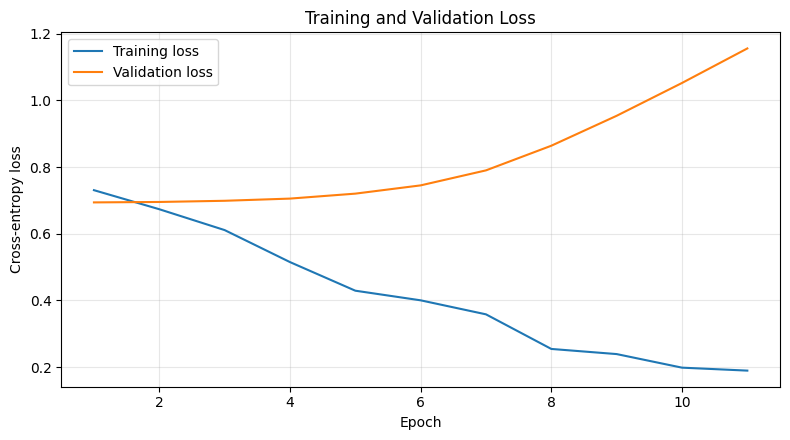

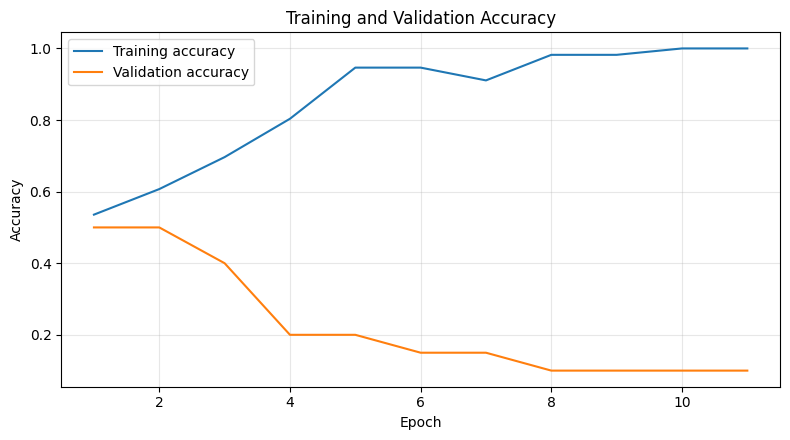

In [6]:
epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(8, 4.5))
plt.plot(epochs, history["train_loss"], label="Training loss")
plt.plot(epochs, history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4.5))
plt.plot(epochs, history["train_acc"], label="Training accuracy")
plt.plot(epochs, history["val_acc"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Evaluate on the held-out validation set
Accuracy alone can hide class-specific errors, so the classification report and confusion matrix are also shown.

Validation accuracy: 0.500

Classification report:
              precision    recall  f1-score   support

    negative       0.50      1.00      0.67        10
    positive       0.00      0.00      0.00        10

    accuracy                           0.50        20
   macro avg       0.25      0.50      0.33        20
weighted avg       0.25      0.50      0.33        20



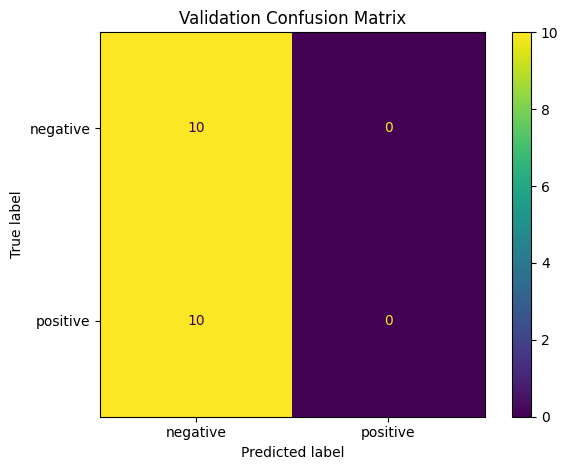

In [7]:
model.eval()
with torch.no_grad():
    val_logits = model(torch.from_numpy(X_val).to(device))
    val_probs = torch.softmax(val_logits, dim=1).cpu().numpy()
    val_predictions = val_probs.argmax(axis=1)

print(f"Validation accuracy: {accuracy_score(y_val_np, val_predictions):.3f}")
print("\nClassification report:")
print(classification_report(
    y_val_np, val_predictions,
    labels=[0, 1],
    target_names=["negative", "positive"],
    zero_division=0
))

cm = confusion_matrix(y_val_np, val_predictions, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["negative", "positive"])
disp.plot()
plt.title("Validation Confusion Matrix")
plt.tight_layout()
plt.show()

## 8. Predict unseen sample inputs with confidence
The confidence score is the model's softmax probability for its selected class. It is not a guarantee that a prediction is correct, especially because this demonstration dataset is small.

In [8]:
def predict_sentiment(texts):
    if isinstance(texts, str):
        texts = [texts]
    features = vectorizer.transform(texts).toarray().astype(np.float32)
    model.eval()
    with torch.no_grad():
        logits = model(torch.from_numpy(features).to(device))
        probabilities = torch.softmax(logits, dim=1).cpu().numpy()

    results = []
    for text, probs in zip(texts, probabilities):
        pred_idx = int(np.argmax(probs))
        results.append({
            "text": text,
            "predicted_sentiment": "positive" if pred_idx == 1 else "negative",
            "confidence": round(float(probs[pred_idx]), 4),
            "negative_probability": round(float(probs[0]), 4),
            "positive_probability": round(float(probs[1]), 4)
        })
    return pd.DataFrame(results)

test_sentences = [
    "The product is excellent and I am very happy",
    "Terrible service and disappointing quality",
    "The app is easy to use and works perfectly",
    "I regret buying this because it broke quickly",
]
display(predict_sentiment(test_sentences))

,text,predicted_sentiment,confidence,negative_probability,positive_probability
0,The product is excellent and I am very happy,negative,0.5265,0.5265,0.4735
1,Terrible service and disappointing quality,negative,0.5232,0.5232,0.4768
2,The app is easy to use and works perfectly,negative,0.5246,0.5246,0.4754
3,I regret buying this because it broke quickly,negative,0.5301,0.5301,0.4699


## 9. Save model artefacts
Save the trained model weights and the TF–IDF vocabulary so the same preprocessing can be reused. Keep the model architecture definition when loading the weights in a separate script.

In [9]:
import pickle
from pathlib import Path

output_dir = Path("text_classifier_artifacts")
output_dir.mkdir(exist_ok=True)

torch.save(model.state_dict(), output_dir / "pytorch_text_classifier.pt")
with open(output_dir / "tfidf_vectorizer.pkl", "wb") as f:
    pickle.dump(vectorizer, f)

print("Saved artefacts to:", output_dir.resolve())
print("Files:", [p.name for p in output_dir.iterdir()])

Saved artefacts to: /text_classifier_artifacts
Files: ['pytorch_text_classifier.pt', 'tfidf_vectorizer.pkl']


## 10. Conclusion
- Text was normalized and converted into TF–IDF features.
- A multilayer PyTorch classifier was trained using cross-entropy loss and AdamW.
- Dropout and Batch Normalization were used as regularization/stabilization techniques.
- Validation loss and accuracy curves were plotted, and held-out metrics were reported.
- Unseen text was classified with confidence scores.

**Limitations:** This notebook uses a small demonstration dataset, so scores may vary and should not be interpreted as real-world performance. To improve the project, train and test on a larger, balanced, representative sentiment dataset; report the dataset source and licence; and keep a separate untouched test set.